<a href="https://colab.research.google.com/github/keerthh129/AIML-Colab/blob/main/rnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from tensorflow.keras.datasets import imdb

# Load IMDB Movie Reviews Dataset
(X_train, y_train), (X_test, y_test) = imdb.load_data()

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("First review:", X_train[0])
print("First label:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000
Testing reviews: 25000
First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 22665, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 21631, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 19193, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 10311, 8, 4, 107, 117, 5952, 15, 256, 4, 31050, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 12118, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1

In [ ]:
print("Total reviews:", len(X_train) + len(X_test))
print("Positive reviews:", sum(y_train) + sum(y_test))
print("Negative reviews:", len(y_train) + len(y_test)
      - sum(y_train) - sum(y_test))

Total reviews: 50000
Positive reviews: 25000
Negative reviews: 25000


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

vocab_size = 10000
max_length = 250

X_train_pad = pad_sequences(
    X_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

Training shape: (25000, 250)
Testing shape: (25000, 250)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Dense,
    Dropout, Bidirectional, SpatialDropout1D
)

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=True
    ),
    SpatialDropout1D(0.2),
    Bidirectional(LSTM(64, dropout=0.2)),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
print("X_train_pad minimum:", X_train_pad.min())
print("X_train_pad maximum:", X_train_pad.max())
print("Embedding input_dim:", model.layers[0].input_dim)

X_train_pad minimum: 0
X_train_pad maximum: 88584
Embedding input_dim: 10000


In [ ]:
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

vocab_size = 10000
max_length = 250

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

X_train_pad = pad_sequences(
    X_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training maximum:", X_train_pad.max())
print("Testing maximum:", X_test_pad.max())
print("Training shape:", X_train_pad.shape)

Training maximum: 9999
Testing maximum: 9999
Training shape: (25000, 250)


In [ ]:
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

vocab_size = 10000
max_length = 250

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

X_train_pad = pad_sequences(
    X_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training maximum:", X_train_pad.max())
print("Testing maximum:", X_test_pad.max())
print("Training shape:", X_train_pad.shape)

Training maximum: 9999
Testing maximum: 9999
Training shape: (25000, 250)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Dense,
    Dropout, Bidirectional, SpatialDropout1D
)

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Embedding(10000, 128, mask_zero=True),
    SpatialDropout1D(0.2),
    Bidirectional(LSTM(64, dropout=0.2)),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model rebuilt successfully!")

Model rebuilt successfully!


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=8,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 226s 703ms/step - accuracy: 0.7780 - loss: 0.4469 - val_accuracy: 0.8714 - val_loss: 0.3150
Epoch 2/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 212s 679ms/step - accuracy: 0.9036 - loss: 0.2411 - val_accuracy: 0.8700 - val_loss: 0.3414
Epoch 3/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 222s 709ms/step - accuracy: 0.9255 - loss: 0.1932 - val_accuracy: 0.8502 - val_loss: 0.4114


In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test,
    verbose=1
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 60s 77ms/step - accuracy: 0.8593 - loss: 0.3299
Test Loss: 0.3299
Test Accuracy: 85.93 %


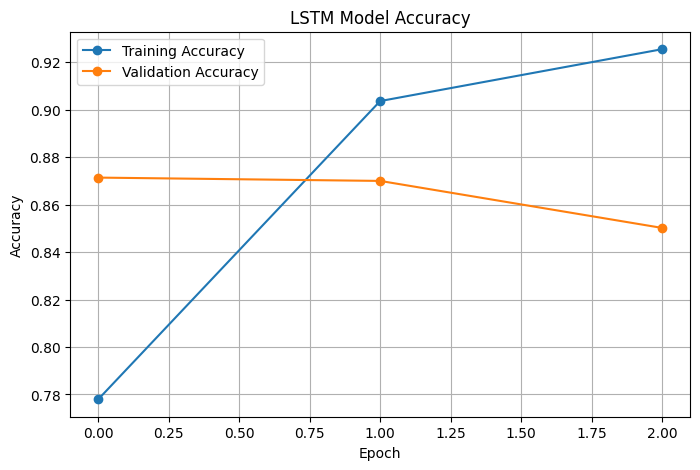

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], marker="o",
         label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o",
         label="Validation Accuracy")

plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

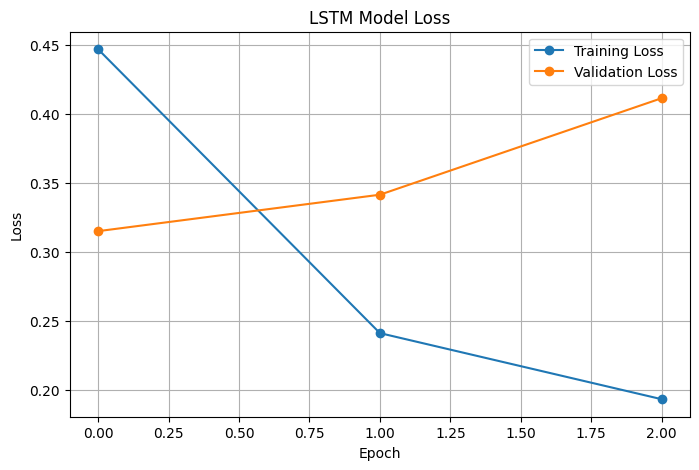

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], marker="o",
         label="Training Loss")
plt.plot(history.history["val_loss"], marker="o",
         label="Validation Loss")

plt.title("LSTM Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import re
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

word_index = imdb.get_word_index()

def predict_sentiment(review):
    words = re.findall(r"[a-zA-Z']+", review.lower())

    sequence = [1]  # Start token

    for word in words:
        index = word_index.get(word)

        if index is None or index + 3 >= 10000:
            sequence.append(2)  # Unknown word
        else:
            sequence.append(index + 3)

    padded_review = pad_sequences(
        [sequence],
        maxlen=250,
        padding="post",
        truncating="post"
    )

    probability = float(
        model.predict(padded_review, verbose=0)[0][0]
    )

    if probability >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Positive Probability:", round(probability, 4))

predict_sentiment("This movie was amazing and very enjoyable")
predict_sentiment("This movie was boring and disappointing")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Review: This movie was amazing and very enjoyable
Predicted Sentiment: Positive
Positive Probability: 0.9551
Review: This movie was boring and disappointing
Predicted Sentiment: Negative
Positive Probability: 0.0385


In [ ]:
model.save("imdb_lstm_model.keras")

print("Model saved successfully!")

Model saved successfully!
